In [1]:
import torch

print("PyTorch版本：", torch.__version__)
print("CUDA是否可用：", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU名称：", torch.cuda.get_device_name(0))

PyTorch版本： 1.12.1+cu102
CUDA是否可用： True
GPU名称： Tesla P100-PCIE-16GB


/home/ma-user/anaconda3/envs/PyTorch-1.12.1/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import sys

!{sys.executable} -m pip uninstall -y peft datasets dill fsspec

Found existing installation: peft 0.4.0
Uninstalling peft-0.4.0:
  Successfully uninstalled peft-0.4.0
Found existing installation: datasets 2.14.6
Uninstalling datasets-2.14.6:
  Successfully uninstalled datasets-2.14.6
Found existing installation: dill 0.4.1
Uninstalling dill-0.4.1:
  Successfully uninstalled dill-0.4.1
Found existing installation: fsspec 2025.10.0
Uninstalling fsspec-2025.10.0:
  Successfully uninstalled fsspec-2025.10.0


In [5]:
import sys

!{sys.executable} -m pip uninstall -y multiprocess
!{sys.executable} -m pip install -q multiprocess==0.70.14

Found existing installation: multiprocess 0.70.19
Uninstalling multiprocess-0.70.19:
  Successfully uninstalled multiprocess-0.70.19


In [5]:
import torch
import transformers
import datasets
import accelerate
import peft
import dill
import multiprocess
import fsspec

print("torch:", torch.__version__)
print("cuda:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("transformers:", transformers.__version__)
print("datasets:", datasets.__version__)
print("accelerate:", accelerate.__version__)
print("peft:", peft.__version__)
print("dill:", dill.__version__)
print("multiprocess:", multiprocess.__version__)
print("fsspec:", fsspec.__version__)

torch: 1.12.1+cu102
cuda: True
GPU: Tesla P100-PCIE-16GB
transformers: 4.32.0
datasets: 2.13.1
accelerate: 0.21.0
peft: 0.2.0
dill: 0.3.6
multiprocess: 0.70.14
fsspec: 2023.6.0


In [19]:
import os

BASE_DIR = "/home/ma-user/work/qwen_poetry_exp"
DATA_DIR = os.path.join(BASE_DIR, "data")
OUTPUT_DIR = os.path.join(BASE_DIR, "outputs")
LORA_DIR = os.path.join(OUTPUT_DIR, "qwen_poetry_lora")
FIG_DIR = os.path.join(OUTPUT_DIR, "figures")
RESULT_DIR = os.path.join(OUTPUT_DIR, "results")

for d in [BASE_DIR, DATA_DIR, OUTPUT_DIR, LORA_DIR, FIG_DIR, RESULT_DIR]:
    os.makedirs(d, exist_ok=True)

print("实验目录创建完成：", BASE_DIR)

实验目录创建完成： /home/ma-user/work/qwen_poetry_exp


In [20]:
import os

data_path = "/home/ma-user/work/qwen_poetry_exp/data/唐诗三百 - small.txt"

print("文件是否存在：", os.path.exists(data_path))

encodings = ["utf-8", "gbk", "gb18030", "ansi"]
lines = None
used_encoding = None

for enc in encodings:
    try:
        with open(data_path, "r", encoding=enc) as f:
            lines = [line.strip() for line in f if line.strip()]
        used_encoding = enc
        break
    except Exception as e:
        print(f"{enc} 读取失败：{e}")

print("成功使用编码：", used_encoding)
print("读取成功，诗句数量：", len(lines))
print("前5行：")
for line in lines[:5]:
    print(line)

文件是否存在： True
utf-8 读取失败：'utf-8' codec can't decode byte 0xc1 in position 0: invalid start byte
成功使用编码： gbk
读取成功，诗句数量： 234
前5行：
寥落古行宫，宫花寂寞红。白头宫女在，闲坐说玄宗。
三日入厨下，洗手作羹汤。未谙姑食性，先遣小姑尝。
红豆生南国，春来发几枝。愿君多采撷，此物最相思。
近寒食雨草萋萋，著麦苗风柳映堤。等是有家归未得，杜鹃休向耳边啼。
空山不见人，但闻人语响。返景入深林，复照青苔上。


In [21]:
from modelscope import snapshot_download

model_dir = snapshot_download(
    "qwen/Qwen-1_8B-Chat",
    cache_dir="/home/ma-user/work/qwen_model"
)

print("模型下载路径：", model_dir)

模型下载路径： /home/ma-user/work/qwen_model/qwen/Qwen-1_8B-Chat


In [22]:
import sys

!{sys.executable} -m pip uninstall -y peft

In [23]:
import sys

!{sys.executable} -m pip install -q peft==0.2.0 --no-deps

In [24]:
import torch
import transformers
import datasets
import accelerate
import peft

print("torch:", torch.__version__)
print("cuda:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("transformers:", transformers.__version__)
print("datasets:", datasets.__version__)
print("accelerate:", accelerate.__version__)
print("peft:", peft.__version__)

torch: 1.12.1+cu102
cuda: True
GPU: Tesla P100-PCIE-16GB
transformers: 4.32.0
datasets: 2.13.1
accelerate: 0.21.0
peft: 0.2.0


In [25]:
from peft import LoraConfig, get_peft_model, TaskType, PeftModel

print("PEFT导入成功")

PEFT导入成功


In [26]:
import os

data_path = "/home/ma-user/work/qwen_poetry_exp/data/唐诗三百 - small.txt"

encodings = ["utf-8", "gbk", "gb18030"]
lines = None
used_encoding = None

for enc in encodings:
    try:
        with open(data_path, "r", encoding=enc) as f:
            lines = [line.strip() for line in f if line.strip()]
        used_encoding = enc
        break
    except Exception as e:
        print(f"{enc} 读取失败：{e}")

print("成功使用编码：", used_encoding)
print("读取成功，诗句数量：", len(lines))
print("前5行：")
for line in lines[:5]:
    print(line)

utf8_data_path = "/home/ma-user/work/qwen_poetry_exp/data/tang_poetry_utf8.txt"

with open(utf8_data_path, "w", encoding="utf-8") as f:
    for line in lines:
        f.write(line + "\n")

print("已转换为UTF-8文件：", utf8_data_path)

utf-8 读取失败：'utf-8' codec can't decode byte 0xc1 in position 0: invalid start byte
成功使用编码： gbk
读取成功，诗句数量： 234
前5行：
寥落古行宫，宫花寂寞红。白头宫女在，闲坐说玄宗。
三日入厨下，洗手作羹汤。未谙姑食性，先遣小姑尝。
红豆生南国，春来发几枝。愿君多采撷，此物最相思。
近寒食雨草萋萋，著麦苗风柳映堤。等是有家归未得，杜鹃休向耳边啼。
空山不见人，但闻人语响。返景入深林，复照青苔上。
已转换为UTF-8文件： /home/ma-user/work/qwen_poetry_exp/data/tang_poetry_utf8.txt


In [27]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_path = model_dir

tokenizer = AutoTokenizer.from_pretrained(
    model_path,
    trust_remote_code=True
)

base_model = AutoModelForCausalLM.from_pretrained(
    model_path,
    device_map="auto",
    torch_dtype=torch.float16,
    trust_remote_code=True
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

base_model.config.use_cache = False
base_model.gradient_checkpointing_enable()
base_model.eval()

print("本地模型加载完成：", model_path)

Loading checkpoint shards: 100%|██████████| 2/2 [00:02<00:00,  1.06s/it]
Using pad_token, but it is not set yet.
Using eos_token, but it is not set yet.


本地模型加载完成： /home/ma-user/work/qwen_model/qwen/Qwen-1_8B-Chat


In [56]:
import torch

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# 生成函数：增加 poetry_prompt，让模型明确只续写诗句
def generate_text(model, prompt, max_new_tokens=40, poetry_prompt=None):
    if poetry_prompt is not None:
        prompt_full = f"{poetry_prompt}\n{prompt}"
    else:
        prompt_full = prompt

    inputs = tokenizer(prompt_full, return_tensors="pt").to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=True,
            temperature=0.7,
            top_p=0.85,
            repetition_penalty=1.15,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    result = tokenizer.decode(outputs[0], skip_special_tokens=True)

    # 去掉前面的提示词，只保留模型续写内容
    result = result.replace(prompt_full, "").strip()

    # 简单截断：如果模型又生成“解析/答案/注释”等内容，就删掉后面
    stop_words = ["解析", "答案", "注释", "赏析", "解释", "本题", "译文"]
    for word in stop_words:
        if word in result:
            result = result.split(word)[0].strip()

    return result


baseline_prompts = [
    "春风吹过江南岸，",
    "明月照孤舟，",
    "山中一夜雨，",
    "落花随水去，",
    "秋风入庭树，",
    "故人别后远，",
    "寒灯照夜雨，",
    "白云生远岫，",
    "江上晚来风，",
    "独坐听松声，"
]

baseline_results = []

poetry_instruction = "请只续写唐诗风格的诗句，不要解释，不要赏析，不要回答题目，只输出诗句："

for p in baseline_prompts:
    result = generate_text(
        base_model,
        p,
        max_new_tokens=40,
        poetry_prompt=poetry_instruction
    )

    # 为了截图更清楚，把原句和续写拼在一起展示
    full_poem = p + result

    baseline_results.append(full_poem)

    print("【输入】", p)
    print("【Baseline输出】", full_poem)
    print("-" * 80)

【输入】 春风吹过江南岸，
【Baseline输出】 春风吹过江南岸，碧草柔柳线牵牛。新燕子双穿日午热，又将绿绕村西宿。中原北望气如山，楼厌鸣鸾已废弦。
--------------------------------------------------------------------------------
【输入】 明月照孤舟，
【Baseline输出】 明月照孤舟，水凉风已秋。残荷当宿露，远雁认空流。接缕斩新蒲，连茄落故洲。想君行转侧，兼以断怀
--------------------------------------------------------------------------------
【输入】 山中一夜雨，
【Baseline输出】 山中一夜雨，树杪百重泉。汉女输橦布，巴人讼芋田。文翁翻教授，不敢倚先贤。但觉江村静，时时有落花。独
--------------------------------------------------------------------------------
【输入】 落花随水去，
【Baseline输出】 落花随水去，空对月相思。此志无超出，悠悠满秋臆。残杯与愁邻，切切废长夜。信是嫦娥使，未闻吴刚折。
--------------------------------------------------------------------------------
【输入】 秋风入庭树，
【Baseline输出】 秋风入庭树，孤客临寒食。怀旧空吟闻笛赋，到乡翻似烂柯人。沉舟侧畔千帆过，病树前头万木春。今日听
--------------------------------------------------------------------------------
【输入】 故人别后远，
【Baseline输出】 故人别后远，岁晚多阴霾。残月凌高树，稀云护夕阳。渡头此怀归，村社去歌谣。迹绝无遗迹，空为地理遐。维
--------------------------------------------------------------------------------
【输入】 寒灯照夜雨，
【Baseline输出】 寒灯照夜雨，深院响疏钟。飞鸟已远去，残秧竟谁中？所愿困无违，终朝望南宫。闷来无所为，明

In [57]:
import pandas as pd
import os

RESULT_DIR = "/home/ma-user/work/qwen_poetry_exp/outputs/results"
os.makedirs(RESULT_DIR, exist_ok=True)

baseline_df = pd.DataFrame({
    "输入提示": baseline_prompts,
    "Baseline输出": baseline_results
})

baseline_save_path = os.path.join(RESULT_DIR, "baseline_results.csv")
baseline_df.to_csv(baseline_save_path, index=False, encoding="utf-8-sig")

print("Baseline结果已保存：", baseline_save_path)
baseline_df

Baseline结果已保存： /home/ma-user/work/qwen_poetry_exp/outputs/results/baseline_results.csv


,输入提示,Baseline输出
0,春风吹过江南岸，,春风吹过江南岸，碧草柔柳线牵牛。新燕子双穿日午热，又将绿绕村西宿。中原北望气如山，楼厌鸣鸾已废弦。
1,明月照孤舟，,明月照孤舟，水凉风已秋。残荷当宿露，远雁认空流。接缕斩新蒲，连茄落故洲。想君行转侧，兼以断怀
2,山中一夜雨，,山中一夜雨，树杪百重泉。汉女输橦布，巴人讼芋田。文翁翻教授，不敢倚先贤。但觉江村静，时时有落花。独
3,落花随水去，,落花随水去，空对月相思。此志无超出，悠悠满秋臆。残杯与愁邻，切切废长夜。信是嫦娥使，未闻吴刚折。
4,秋风入庭树，,秋风入庭树，孤客临寒食。怀旧空吟闻笛赋，到乡翻似烂柯人。沉舟侧畔千帆过，病树前头万木春。今日听
5,故人别后远，,故人别后远，岁晚多阴霾。残月凌高树，稀云护夕阳。渡头此怀归，村社去歌谣。迹绝无遗迹，空为地理遐。维
6,寒灯照夜雨，,寒灯照夜雨，深院响疏钟。飞鸟已远去，残秧竟谁中？所愿困无违，终朝望南宫。闷来无所为，明朝还有穷。渡
7,白云生远岫，,白云生远岫，归思在东篱。残菊侵门露，孤兰掩院苔。碧山终日暮，青帝不归来。自是过寻丈，隔这种方...
8,江上晚来风，,江上晚来风，烟光残照里。乱鸦啼远冬，独树明秋色。岁月犹西入，离亲不可闻。寒蝉残梦醒，铅粉泪痕新。
9,独坐听松声，,独坐听松声，稍闻鸟相鸣。空蒙每一梦，万事皆吾身。\n多知眼前苦，少欲后世宁。他山非故林，别我...


In [30]:
import re
from datasets import Dataset

data_path = "/home/ma-user/work/qwen_poetry_exp/data/tang_poetry_utf8.txt"

with open(data_path, "r", encoding="utf-8") as f:
    raw_lines = [line.strip() for line in f if line.strip()]

def clean_text(text):
    text = text.strip()
    text = re.sub(r"\s+", "", text)
    text = re.sub(r"[A-Za-z0-9~^`|]", "", text)
    return text

poems = []
for line in raw_lines:
    line = clean_text(line)
    if len(line) >= 8:
        poems.append(line)

# P100 16GB 为了省时间和显存，先取前200条即可
poems = poems[:200]

formatted_texts = []
for poem in poems:
    formatted_texts.append(f"请续写一首唐诗风格的诗句：\n{poem}")

dataset = Dataset.from_dict({"text": formatted_texts})
split_dataset = dataset.train_test_split(test_size=0.1, seed=42)

train_dataset = split_dataset["train"]
eval_dataset = split_dataset["test"]

print("训练集数量：", len(train_dataset))
print("验证集数量：", len(eval_dataset))
print("样例：")
print(train_dataset[0]["text"])

训练集数量： 180
验证集数量： 20
样例：
请续写一首唐诗风格的诗句：
独在异乡为异客，每逢佳节倍思亲。遥知兄弟登高处，遍插茱萸少一人。


In [31]:
print("pad_token:", tokenizer.pad_token)
print("pad_token_id:", tokenizer.pad_token_id)
print("eos_token:", tokenizer.eos_token)
print("eos_token_id:", tokenizer.eos_token_id)

# Qwen 常用的结束符
special_token = "<|endoftext|>"
special_id = tokenizer.convert_tokens_to_ids(special_token)

print("<|endoftext|> id:", special_id)

Using pad_token, but it is not set yet.
Using eos_token, but it is not set yet.


pad_token: None
pad_token_id: None
eos_token: None
eos_token_id: None
<|endoftext|> id: 151643


In [32]:
MAX_LENGTH = 64

# 选择一个可用的 pad_id
if tokenizer.eos_token_id is not None:
    PAD_ID = tokenizer.eos_token_id
else:
    PAD_ID = tokenizer.convert_tokens_to_ids("<|endoftext|>")

print("当前使用 PAD_ID:", PAD_ID)

def tokenize_function(examples):
    input_ids_list = []
    attention_mask_list = []
    labels_list = []

    for text in examples["text"]:
        ids = tokenizer.encode(
            text,
            add_special_tokens=True,
            truncation=True,
            max_length=MAX_LENGTH
        )

        # 截断
        ids = ids[:MAX_LENGTH]

        # 手动补齐
        pad_len = MAX_LENGTH - len(ids)

        input_ids = ids + [PAD_ID] * pad_len
        attention_mask = [1] * len(ids) + [0] * pad_len

        # labels 中 padding 部分设为 -100，训练时忽略
        labels = ids + [-100] * pad_len

        input_ids_list.append(input_ids)
        attention_mask_list.append(attention_mask)
        labels_list.append(labels)

    return {
        "input_ids": input_ids_list,
        "attention_mask": attention_mask_list,
        "labels": labels_list
    }

tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

tokenized_eval = eval_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

print("训练集分词后字段：", tokenized_train[0].keys())
print("input_ids长度：", len(tokenized_train[0]["input_ids"]))
print("attention_mask长度：", len(tokenized_train[0]["attention_mask"]))
print("labels长度：", len(tokenized_train[0]["labels"]))
print("分词完成")

当前使用 PAD_ID: 151643


训练集分词后字段： dict_keys(['input_ids', 'attention_mask', 'labels'])
input_ids长度： 64
attention_mask长度： 64
labels长度： 64
分词完成


In [ ]:
# 关闭 gradient checkpointing，避免 LoRA 训练时 loss 无梯度
try:
    base_model.gradient_checkpointing_disable()
    print("已关闭 gradient checkpointing")
except Exception as e:
    print("关闭 gradient checkpointing 时提示：", e)

base_model.config.use_cache = False
base_model.train()

In [79]:
import gc
import torch

torch.cuda.empty_cache()
gc.collect()
print("显存清理完成")

显存清理完成


In [ ]:
import torch
import torch.nn as nn

print("检查可以注入 LoRA 的模块：")

for name, module in base_model.named_modules():
    if name.endswith("c_attn") or name.endswith("c_proj"):
        print(name, "----", type(module))

In [15]:
target_modules = ["c_attn", "c_proj"]

In [16]:
from peft import LoraConfig, get_peft_model, TaskType

# 重要：只注入真正的投影层，不要写 attn
target_modules = ["c_attn", "c_proj"]

lora_config = LoraConfig(
    r=8,
    lora_alpha=32,
    target_modules=target_modules,
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.CAUSAL_LM
)

lora_model = get_peft_model(base_model, lora_config)
lora_model.print_trainable_parameters()

trainable params: 3809280 || all params: 1840637952 || trainable%: 0.2069543331898005


In [35]:
# 解决 Qwen tokenizer 没有 pad_token 的问题
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

if tokenizer.pad_token_id is None:
    tokenizer.pad_token_id = tokenizer.eos_token_id

# 同步到模型配置里
base_model.config.pad_token_id = tokenizer.pad_token_id
lora_model.config.pad_token_id = tokenizer.pad_token_id

print("pad_token:", tokenizer.pad_token)
print("pad_token_id:", tokenizer.pad_token_id)
print("eos_token:", tokenizer.eos_token)
print("eos_token_id:", tokenizer.eos_token_id)

Using pad_token, but it is not set yet.
Using eos_token, but it is not set yet.
Using pad_token, but it is not set yet.
Using eos_token, but it is not set yet.


pad_token: None
pad_token_id: None
eos_token: None
eos_token_id: None


In [37]:
# ===== 强制修复 Qwen tokenizer 没有 pad_token 的问题 =====

print("修复前：")
print("pad_token:", tokenizer.pad_token)
print("pad_token_id:", tokenizer.pad_token_id)
print("eos_token:", tokenizer.eos_token)
print("eos_token_id:", tokenizer.eos_token_id)

# Qwen 常见结束符
possible_pad_tokens = [
    "<|endoftext|>",
    "<|im_end|>",
    tokenizer.eos_token
]

pad_token = None

for tok in possible_pad_tokens:
    if tok is None:
        continue
    try:
        tok_id = tokenizer.convert_tokens_to_ids(tok)
        if tok_id is not None and tok_id != tokenizer.unk_token_id and tok_id >= 0:
            pad_token = tok
            break
    except Exception:
        pass

# 如果已有结束符，就复用结束符作为 pad_token
if pad_token is not None:
    tokenizer.pad_token = pad_token
else:
    # 如果完全找不到，就新增一个 [PAD]
    tokenizer.add_special_tokens({"pad_token": "[PAD]"})
    pad_token = "[PAD]"

print("\n修复后：")
print("pad_token:", tokenizer.pad_token)
print("pad_token_id:", tokenizer.pad_token_id)
print("eos_token:", tokenizer.eos_token)
print("eos_token_id:", tokenizer.eos_token_id)

# 同步到模型配置
base_model.config.pad_token_id = tokenizer.pad_token_id

try:
    lora_model.config.pad_token_id = tokenizer.pad_token_id
except:
    pass

# 如果新增了 [PAD]，需要扩展模型词表
try:
    base_model.resize_token_embeddings(len(tokenizer))
    print("已同步模型词表大小")
except Exception as e:
    print("词表大小无需调整或调整失败：", e)

Using pad_token, but it is not set yet.
Using eos_token, but it is not set yet.
Using eos_token, but it is not set yet.
Using eos_token, but it is not set yet.
You are resizing the embedding layer without providing a `pad_to_multiple_of` parameter. This means that the new embeding dimension will be 151851. This might induce some performance reduction as *Tensor Cores* will not be available. For more details  about this, or help on choosing the correct value for resizing, refer to this guide: https://docs.nvidia.com/deeplearning/performance/dl-performance-matrix-multiplication/index.html#requirements-tc


修复前：
pad_token: None
pad_token_id: None
eos_token: None
eos_token_id: None

修复后：
pad_token: <|endoftext|>
pad_token_id: 151643
eos_token: None
eos_token_id: None
已同步模型词表大小


In [38]:
MAX_LENGTH = 64

def tokenize_function(examples):
    outputs = tokenizer(
        examples["text"],
        truncation=True,
        max_length=MAX_LENGTH,
        padding="max_length"
    )
    outputs["labels"] = outputs["input_ids"].copy()
    return outputs

tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

tokenized_eval = eval_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

print("分词完成")
print(tokenized_train[0].keys())

分词完成
dict_keys(['input_ids', 'token_type_ids', 'attention_mask', 'labels'])


In [41]:
# ===== 修复 LoRA 训练时 loss 无梯度的问题 =====

import torch

# 1. 确保模型处于训练模式
lora_model.train()

# 2. 关闭 gradient checkpointing，避免输入没有梯度导致反传失败
try:
    lora_model.gradient_checkpointing_disable()
    print("已关闭 lora_model gradient checkpointing")
except Exception as e:
    print("lora_model 无 gradient_checkpointing_disable:", e)

try:
    base_model.gradient_checkpointing_disable()
    print("已关闭 base_model gradient checkpointing")
except Exception as e:
    print("base_model 无 gradient_checkpointing_disable:", e)

# 3. Qwen 有些版本把 gradient_checkpointing 放在 transformer 里面
try:
    lora_model.base_model.model.transformer.gradient_checkpointing = False
    print("已关闭 transformer.gradient_checkpointing")
except Exception as e:
    print("未找到 transformer.gradient_checkpointing:", e)

# 4. 训练时关闭 use_cache
try:
    lora_model.config.use_cache = False
    print("已设置 lora_model.config.use_cache = False")
except Exception as e:
    print("设置 lora_model use_cache 失败:", e)

try:
    base_model.config.use_cache = False
    print("已设置 base_model.config.use_cache = False")
except Exception as e:
    print("设置 base_model use_cache 失败:", e)

# 5. 确保 LoRA 参数 requires_grad=True
for name, param in lora_model.named_parameters():
    if "lora_" in name:
        param.requires_grad = True

# 6. 打印可训练参数，必须大于 0
trainable_params = 0
all_params = 0

for name, param in lora_model.named_parameters():
    all_params += param.numel()
    if param.requires_grad:
        trainable_params += param.numel()

print("可训练参数量:", trainable_params)
print("总参数量:", all_params)
print("可训练比例:", trainable_params / all_params * 100, "%")

# 7. 检查是否真的有可训练参数
if trainable_params == 0:
    raise ValueError("当前模型没有任何可训练参数，LoRA 没有正确注入。")

已关闭 lora_model gradient checkpointing
已关闭 base_model gradient checkpointing
已关闭 transformer.gradient_checkpointing
已设置 lora_model.config.use_cache = False
已设置 base_model.config.use_cache = False
可训练参数量: 3809280
总参数量: 1840637952
可训练比例: 0.20695433318980047 %


In [50]:
from transformers import TrainingArguments, Trainer, DataCollatorForLanguageModeling

data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False
)

training_args = TrainingArguments(
    output_dir="/home/ma-user/work/qwen_poetry_exp/outputs/checkpoints",
    learning_rate=5e-5,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=4,
    num_train_epochs=20,
    fp16=True,
    logging_steps=5,
    evaluation_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    report_to="none",
    remove_unused_columns=False,
    gradient_checkpointing=False
)

trainer = Trainer(
    model=lora_model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_eval,
    data_collator=data_collator,
    tokenizer=tokenizer
)

print("Trainer 重新配置完成")

Trainer 重新配置完成


In [51]:
train_result = trainer.train()
print(train_result)

Epoch,Training Loss,Validation Loss
1,0.268200,0.528614
2,0.141100,0.538093
3,0.151700,0.512379
4,0.200600,0.531687
5,0.130800,0.517667
6,0.150500,0.505424
7,0.130700,0.522399
8,0.124800,0.516699
9,0.128000,0.512518
10,0.140200,0.513194


TrainOutput(global_step=900, training_loss=0.1352225813600752, metrics={'train_runtime': 574.0496, 'train_samples_per_second': 6.271, 'train_steps_per_second': 1.568, 'total_flos': 2114102860185600.0, 'train_loss': 0.1352225813600752, 'epoch': 20.0})


In [52]:
lora_save_path = "/home/ma-user/work/qwen_poetry_exp/outputs/qwen_poetry_lora"

trainer.model.save_pretrained(lora_save_path)
tokenizer.save_pretrained(lora_save_path)

print("LoRA模型和tokenizer已保存：", lora_save_path)

LoRA模型和tokenizer已保存： /home/ma-user/work/qwen_poetry_exp/outputs/qwen_poetry_lora


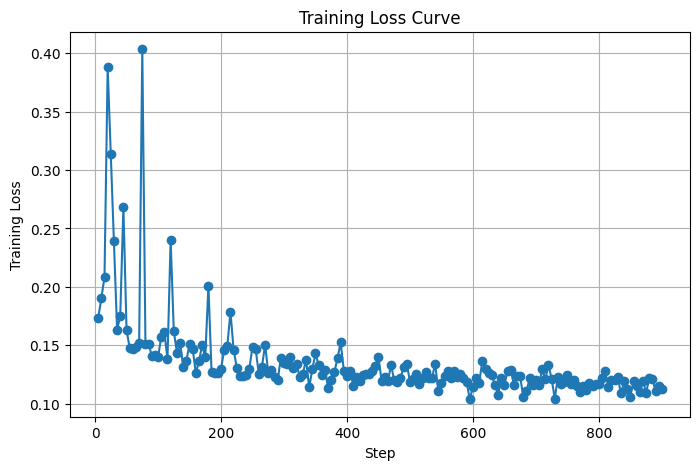

In [53]:
import matplotlib.pyplot as plt
import pandas as pd

# 从 trainer.state.log_history 提取 loss
log_history = trainer.state.log_history
loss_records = [
    {"step": item.get("step"), "epoch": item.get("epoch"), "loss": item.get("loss")}
    for item in log_history if "loss" in item
]

loss_df = pd.DataFrame(loss_records)

plt.figure(figsize=(8,5))
plt.plot(loss_df["step"], loss_df["loss"], marker='o')
plt.xlabel("Step")
plt.ylabel("Training Loss")
plt.title("Training Loss Curve")
plt.grid(True)
plt.savefig("/home/ma-user/work/qwen_poetry_exp/outputs/figures/train_loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()

In [62]:
from peft import PeftModel
import torch
import pandas as pd

# 重新加载 LoRA 模型
lora_model = lora_model.to(torch.float32)
lora_model.eval()
base_model.eval()

test_prompts = [
    "春风吹过江南岸，",
    "明月照孤舟，",
    "山中一夜雨，",
    "落花随水去，",
    "秋风入庭树，",
    "故人别后远，",
    "寒灯照夜雨，",
    "白云生远岫，",
    "江上晚来风，",
    "独坐听松声，"
]

# 生成函数增加 poetry_prompt 参数
def generate(model, prompt, max_new_tokens=50, poetry_prompt=None):
    if poetry_prompt is not None:
        prompt_full = f"{poetry_prompt}\n{prompt}"
    else:
        prompt_full = prompt

    inputs = tokenizer(prompt_full, return_tensors="pt").to(model.device)

    # 如果模型是 fp16，输入也转 fp16
    if model.dtype == torch.float16:
        inputs = {k: v.to(torch.float16) if v.dtype == torch.float32 else v for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=True,
            temperature=0.65,
            top_p=0.8,
            repetition_penalty=1.2,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    result = tokenizer.decode(outputs[0], skip_special_tokens=True)

    # 去掉 prompt，只保留续写
    if poetry_prompt is not None:
        result = result.replace(prompt_full, "").strip()

    # 简单截断：如果生成了“解析/答案/注释”等内容，去掉后面
    stop_words = ["解析", "答案", "注释", "赏析", "解释", "本题", "译文"]
    for word in stop_words:
        if word in result:
            result = result.split(word)[0].strip()

    return result


compare_results = []
poetry_instruction = "请只续写唐诗风格的诗句，不要解释，不要赏析，不要回答题目，只输出诗句："

for idx, prompt in enumerate(test_prompts, 1):
    baseline_output = generate(base_model, prompt, max_new_tokens=50, poetry_prompt=poetry_instruction)
    lora_output = generate(lora_model, prompt, max_new_tokens=50, poetry_prompt=poetry_instruction)

    compare_results.append({
        "序号": idx,
        "输入提示": prompt,
        "Baseline输出": baseline_output,
        "LoRA微调输出": lora_output
    })

    print(f"案例 {idx}")
    print("【输入】", prompt)
    print("【Baseline】", baseline_output)
    print("【LoRA微调】", lora_output)
    print("-"*80)

# 保存对比结果
df_compare = pd.DataFrame(compare_results)
df_compare.to_csv("/home/ma-user/work/qwen_poetry_exp/outputs/results/baseline_lora_compare.csv",
                  index=False, encoding="utf-8-sig")

案例 1
【输入】 春风吹过江南岸，
【Baseline】 明月装饰了天。这首诗是唐代诗人刘禹锡的作品《乌衣巷》。
朱雀桥边野草花，乌衣巷口夕阳斜。旧时王谢堂前燕，飞入寻常百姓家。
【LoRA微调】 留下了万千思念情。折柳赠别空自怜，此恨绵绵无绝期。白居易《赋得古原草送别》：离离原上草，一岁一枯荣。野火烧不尽，
--------------------------------------------------------------------------------
案例 2
【输入】 明月照孤舟，
【Baseline】 水凉凉如水。不知谁家子，瑟瑟夜半流。

独坐空堂上，寂寞无相亲。夕阳人已远，独树月还明。应是隔门莺，苦唤
【LoRA微调】 水凉风已秋。残宵纵酒醒，入骨那知愁。半枕露华红，遥闻平海流。田家旧邻近，夜话未曾休。

今逢白日影，万里总南
--------------------------------------------------------------------------------
案例 3
【输入】 山中一夜雨，
【Baseline】 树杪百重泉。汉女输橦布，巴人讼芋田。文翁翻教授，不敢倚先贤。薄贡无补处，终然抱古心。木兰当户织，不闻机杼
【LoRA微调】 树杪百重泉。汉女输橦布，巴人讼芋田。文翁翻教授，不敢倚先贤。薄命有来日，丰年得此财。永结无情游，相期邈云汉
--------------------------------------------------------------------------------
案例 4
【输入】 落花随水去，
【Baseline】 空巷万人歌。三日行万里，狂风吹我归。西宾无故意，南国有青山。别离方知相思苦，且将金缕赠深情。鸣鸾架广阁，云汉横
【LoRA微调】 空染小桥烟。春将酒添劝，秋共泪别难。落叶他乡树，寒云远近山。物是人非事事休，欲语泪先流。独上江楼思悄然，
--------------------------------------------------------------------------------
案例 5
【输入】 秋风入庭树，
【Baseline】 孤客临寒食。怀旧空吟闻笛赋，到乡翻似烂柯人。沉舟侧畔千帆过，病树前头万木春。今日听君歌一曲，暂凭杯酒长
【LoR